### CẤU HÌNH LOGGING (GHI RA CONSOLE + FILE LOG)

In [99]:
from pathlib import Path
import logging
import sys
import os

LOG_DIR = Path("../docs/logs")
LOG_DIR.mkdir(parents=True, exist_ok=True)

LOG_FILE = LOG_DIR / "practice4.log"

log = logging.getLogger("Practice4")
log.setLevel(logging.INFO)
log.propagate = False

# Xóa handler cũ nếu chạy lại cell trong Jupyter
if log.hasHandlers():
    log.handlers.clear()

formatter = logging.Formatter(
    fmt="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S"
)

file_handler = logging.FileHandler(
    LOG_FILE,
    mode="w",
    encoding="utf-8"
)
file_handler.setFormatter(formatter)

log.addHandler(file_handler)
log.info("Khởi tạo hệ thống logging thành công.")
log.info("Log file: %s", LOG_FILE.resolve())

### Khởi tạo thư viện

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from pathlib import Path

color_pal = sns.color_palette()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

### Đọc dữ liệu

In [101]:
DATA_PATH = Path("../datasets")
processed_file = DATA_PATH / "processed" / "electricity_load_weather_hourly.csv"

In [102]:
df = pd.read_csv(processed_file)

df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.sort_values("time").reset_index(drop=True)
num_cols = ["load", "temperature", "humidity", "wind_speed"]

df.head()

,time,load,temperature,humidity,wind_speed
0,2014-12-31 23:00:00+00:00,25385.0,-5.825,63.0,1.0
1,2015-01-01 00:00:00+00:00,24382.0,-5.825,63.0,1.0
2,2015-01-01 01:00:00+00:00,22734.0,-6.964,64.0,1.0
3,2015-01-01 02:00:00+00:00,21286.0,-6.964,64.0,1.0
4,2015-01-01 03:00:00+00:00,20264.0,-6.964,64.0,1.0


In [103]:
log.info("Khởi tạo cấu hình hiển thị biểu đồ thành công.")

log.info("Bắt đầu đọc dữ liệu từ: %s", processed_file)

log.info("Đọc dữ liệu thành công.")
log.info("Kích thước ban đầu: %d dòng x %d cột", df.shape[0], df.shape[1])

log.info("Chuyển đổi cột time sang datetime thành công.")
log.info(
    "Khoảng thời gian dữ liệu: %s -> %s",
    df["time"].min(),
    df["time"].max()
)

log.info("Danh sách cột dữ liệu:")
log.info("%s", df.columns.tolist())

log.info("Số lượng giá trị thiếu theo cột:")
log.info("\n%s", df.isna().sum().to_string())

time_diffs = df["time"].diff().dropna().value_counts()
log.info("Phân bố bước nhảy thời gian:")
log.info("\n%s", time_diffs.to_string())

desc = df[num_cols].describe().T.round(2)
log.info("Thống kê mô tả các biến số:")
log.info("\n%s", desc.to_string())

log.info("Hoàn thành bước khám phá tổng quan dữ liệu.")

In [104]:
print("=== TỔNG QUAN DỮ LIỆU ===")
print(f"Kích thước: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Khung thời gian: {df['time'].min()} -> {df['time'].max()}")
print("Kiểm tra bước nhảy thời gian (đảm bảo liên tục 1 giờ):")
print(df["time"].diff().value_counts())
print("\nThống kê mô tả:")
display(desc)

=== TỔNG QUAN DỮ LIỆU ===
Kích thước: 35,064 dòng x 5 cột
Khung thời gian: 2014-12-31 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00
Kiểm tra bước nhảy thời gian (đảm bảo liên tục 1 giờ):
time
0 days 01:00:00    35063
Name: count, dtype: int64

Thống kê mô tả:


,count,mean,std,min,25%,50%,75%,max
load,35064.0,28698.28,4575.83,18041.00,24807.0,28902.00,32194.25,41015.00
temperature,35064.0,15.13,9.33,-9.02,8.0,13.78,21.80,40.18
humidity,35064.0,58.73,24.88,0.00,38.0,59.00,81.00,100.00
wind_speed,35064.0,2.43,1.97,0.00,1.0,2.00,3.00,18.00


### Kiểm tra Missing Values, Dữ liệu trùng lặp & Lỗi cảm biến

In [105]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(4)
})
log.info("Bảng kiểm tra Missing Values:\n%s", missing_summary.to_string())
display(missing_summary)

,Missing Count,Missing (%)
time,0,0.0
load,0,0.0
temperature,0,0.0
humidity,0,0.0
wind_speed,0,0.0


In [106]:
dup_rows = int(df.duplicated().sum())
dup_times = int(df["time"].duplicated().sum())
log.info("Số dòng trùng lặp hoàn toàn: %d | Số mốc thời gian trùng lặp: %d", dup_rows, dup_times)

In [107]:
# Kiểm tra bất thường cảm biến ẩn (cả temperature và humidity cùng rơi về 0)
sensor_anomalies = df[(df["temperature"] == 0) & (df["humidity"] == 0)]
if not sensor_anomalies.empty:
    log.warning(
        "Phát hiện %d điểm nghi ngờ lỗi cảm biến (temperature == 0 & humidity == 0):\n%s",
        len(sensor_anomalies),
        sensor_anomalies[["time", "load", "temperature", "humidity", "wind_speed"]].to_string()
    )
    display(sensor_anomalies[["time", "load", "temperature", "humidity", "wind_speed"]])

,time,load,temperature,humidity,wind_speed
2116,2015-03-30 03:00:00+00:00,21335.0,0.0,0.0,1.0
2124,2015-03-30 11:00:00+00:00,31578.0,0.0,0.0,3.0


### Kiểm tra Outliers

In [108]:
outlier_rows = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_low = int((df[col] < lower).sum())
    n_high = int((df[col] > upper).sum())
    pct = round((n_low + n_high) / len(df) * 100, 2)

    outlier_rows.append({
        "Feature": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Low Outliers": n_low,
        "High Outliers": n_high,
        "Outlier (%)": pct
    })
    log.info(
        "Biến %-11s | IQR Bounds=[%.2f, %.2f] | Low=%d, High=%d (%.2f%%)",
        col, lower, upper, n_low, n_high, pct
    )

In [109]:
outlier_df = pd.DataFrame(outlier_rows)
display(outlier_df)

,Feature,Lower Bound,Upper Bound,Low Outliers,High Outliers,Outlier (%)
0,load,13726.12,43275.12,0,0,0.00
1,temperature,-12.70,42.50,0,0,0.00
2,humidity,-26.50,145.50,0,0,0.00
3,wind_speed,-2.00,6.00,0,1705,4.86


#### Vẽ Boxpllot cho Outliers

In [110]:
def create_features(df):
    """
    Tạo các đặc trưng chuỗi thời gian dựa trên cột thời gian.
    """
    df = df.copy()

    df["hour"] = df["time"].dt.hour
    df["dayofweek"] = df["time"].dt.dayofweek
    df["quarter"] = df["time"].dt.quarter
    df["month"] = df["time"].dt.month
    df["year"] = df["time"].dt.year
    df["dayofyear"] = df["time"].dt.dayofyear
    df["is_weekend"] = df["dayofweek"].isin([5, 6])

    return df

In [111]:
df_features = create_features(df)
df_features.set_index("time")
df_features.head()

,time,load,temperature,humidity,wind_speed,hour,dayofweek,quarter,month,year,dayofyear,is_weekend
0,2014-12-31 23:00:00+00:00,25385.0,-5.825,63.0,1.0,23,2,4,12,2014,365,False
1,2015-01-01 00:00:00+00:00,24382.0,-5.825,63.0,1.0,0,3,1,1,2015,1,False
2,2015-01-01 01:00:00+00:00,22734.0,-6.964,64.0,1.0,1,3,1,1,2015,1,False
3,2015-01-01 02:00:00+00:00,21286.0,-6.964,64.0,1.0,2,3,1,1,2015,1,False
4,2015-01-01 03:00:00+00:00,20264.0,-6.964,64.0,1.0,3,3,1,1,2015,1,False


Text(0.5, 1.0, 'Load by Hour')

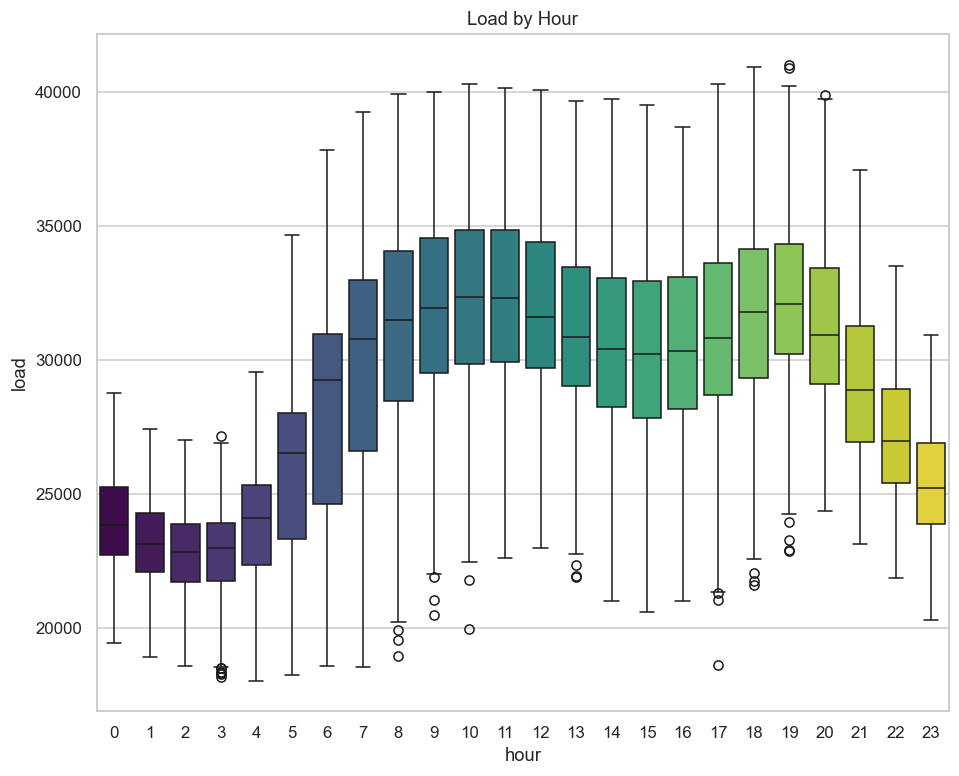

In [112]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=df_features,
    x="hour",
    y="load",
    hue="hour",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Hour")

Text(0.5, 1.0, 'Load by Day of Week')

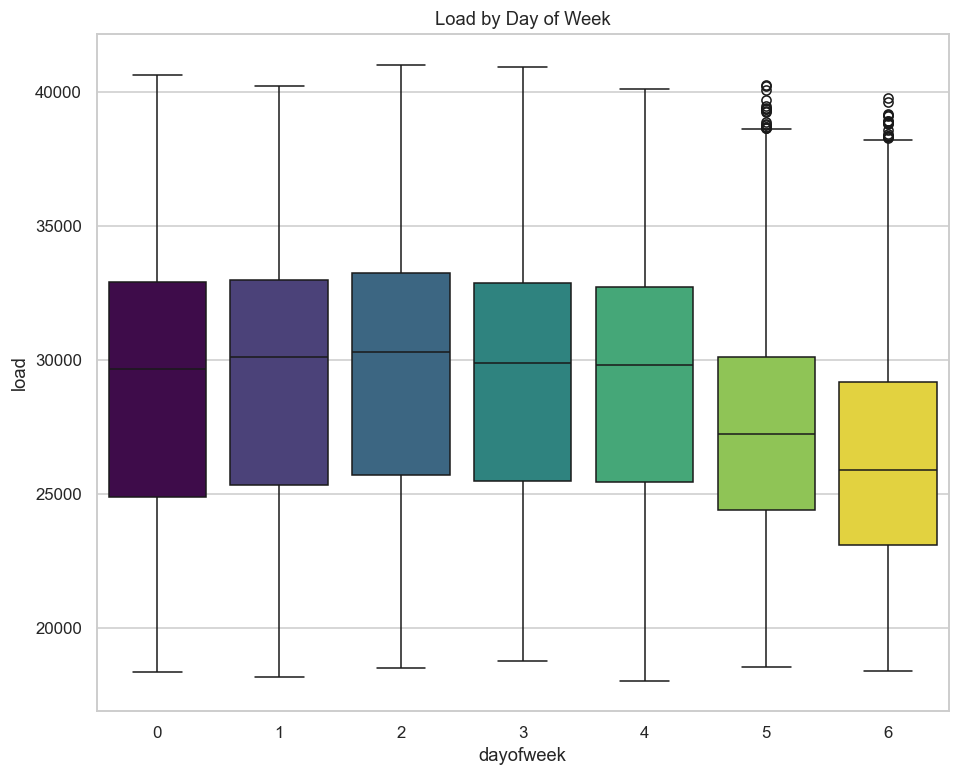

In [113]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=df_features,
    x="dayofweek",
    y="load",
    hue="dayofweek",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Day of Week")

Text(0.5, 1.0, 'Load by Month')

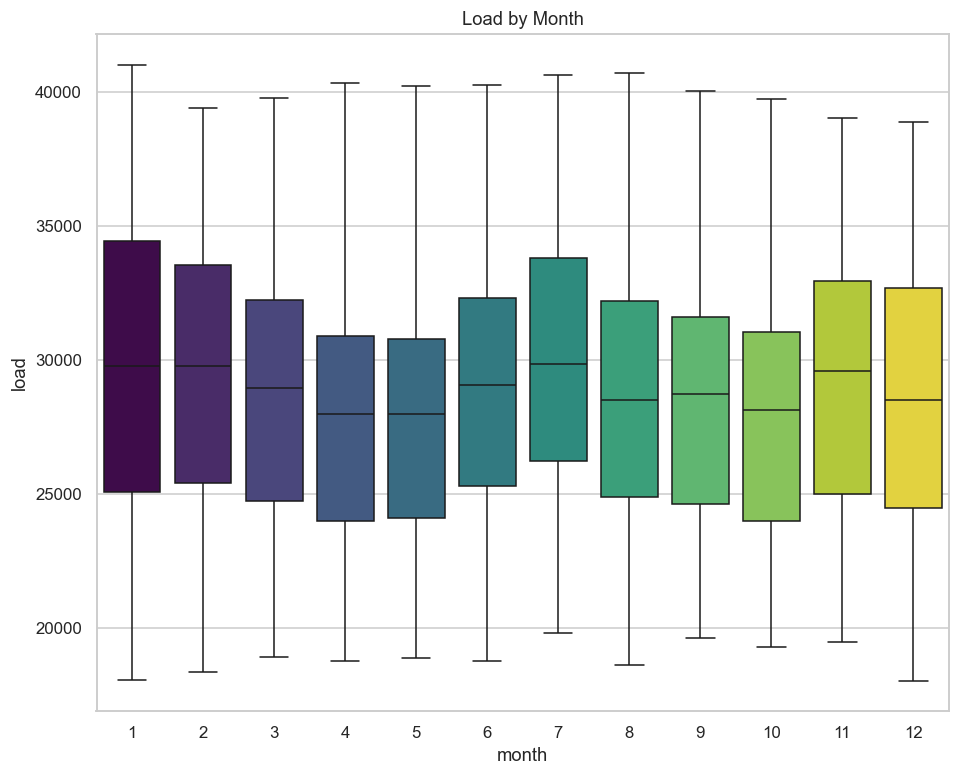

In [114]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=df_features,
    x="month",
    y="load",
    hue="month",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Month")

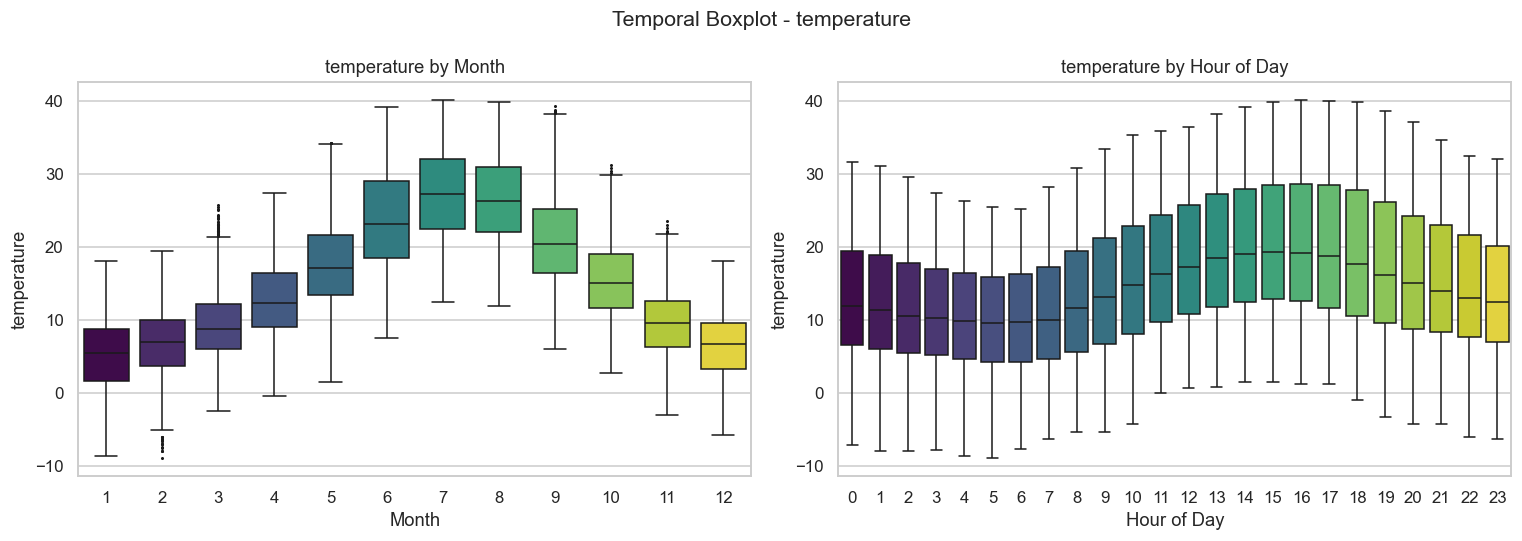

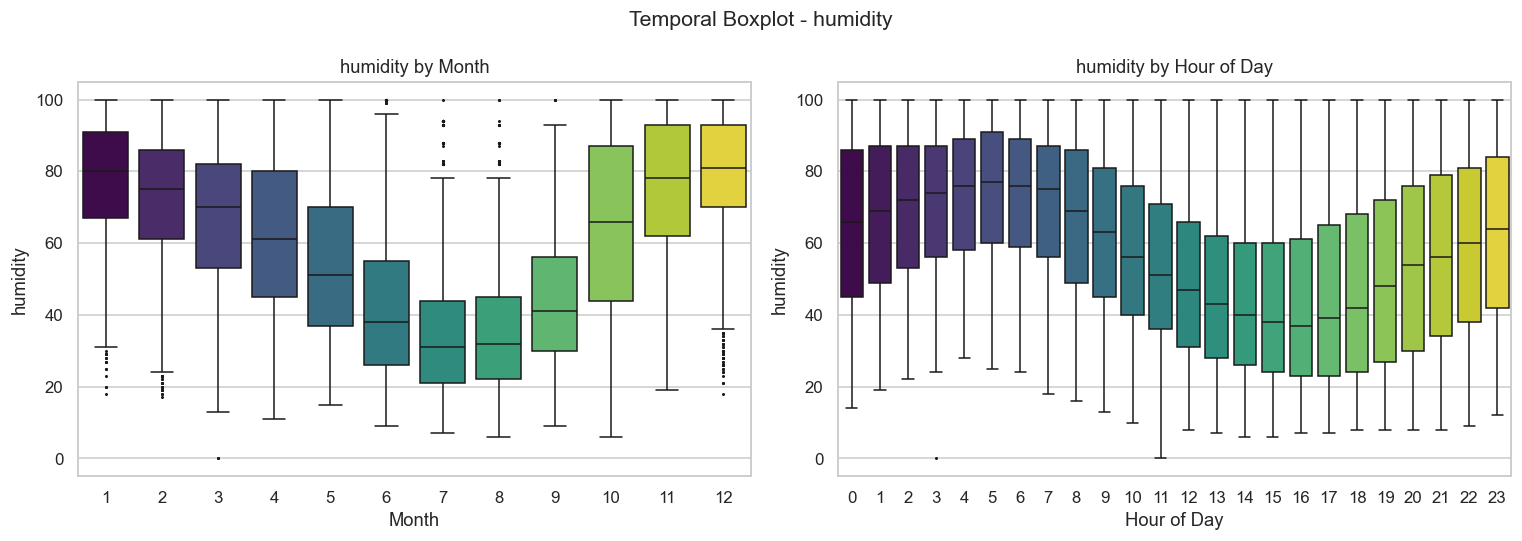

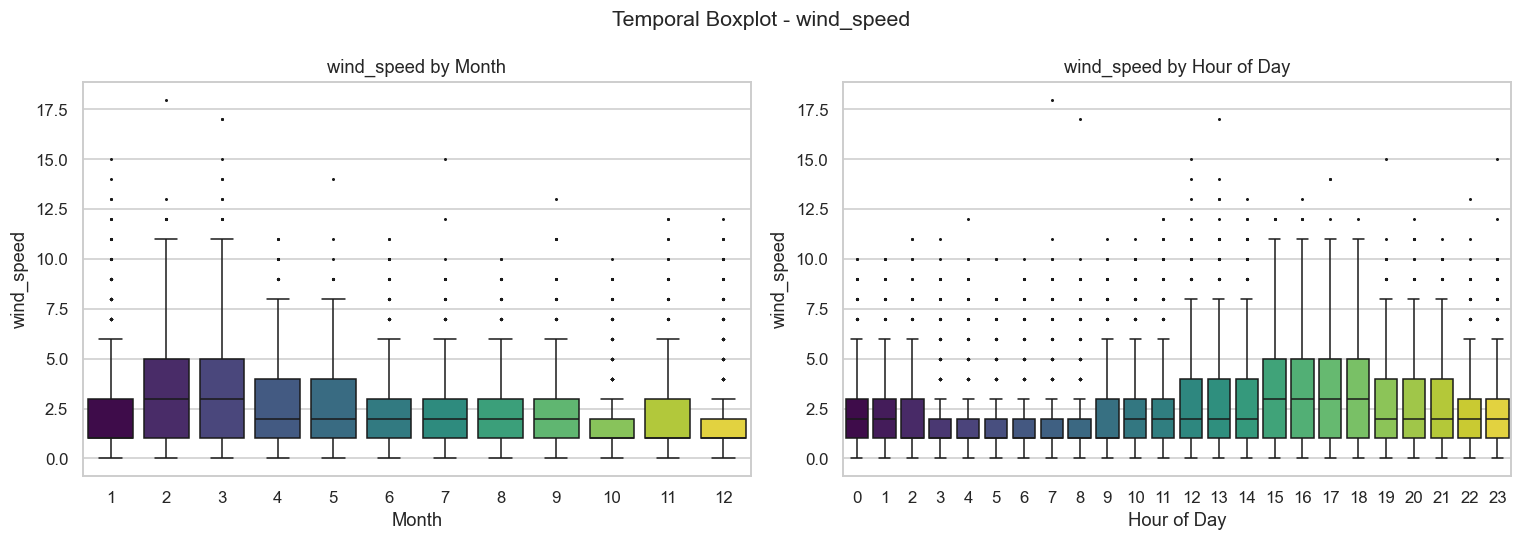

In [115]:
# Các đặc trưng thời gian dùng để phân tích từng biến
temporal_groups = {
    "temperature": ["month", "hour"],
    "humidity": ["month", "hour"],
    "wind_speed": ["month", "hour"]
}

orders = {
    "month": list(range(1, 13)),
    "hour": list(range(24))
}

group_labels = {
    "month": "Month",
    "hour": "Hour of Day"
}

# Vẽ boxplot riêng cho từng biến
for col, groups in temporal_groups.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, group in zip(axes, groups):
        sns.boxplot(
            data=df_features,
            x=group,
            y=col,
            hue=group,
            order=orders[group],
            hue_order=orders[group],
            palette="viridis",
            legend=False,
            dodge=False,
            ax=ax,
            showfliers=True,
            fliersize=1
        )
        ax.set_title(f"{col} by {group_labels[group]}")
        ax.set_xlabel(group_labels[group])
        ax.set_ylabel(col)
    fig.suptitle(
        f"Temporal Boxplot - {col}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

#### **Biểu đồ điện năng tiêu thụ theo thời gian**

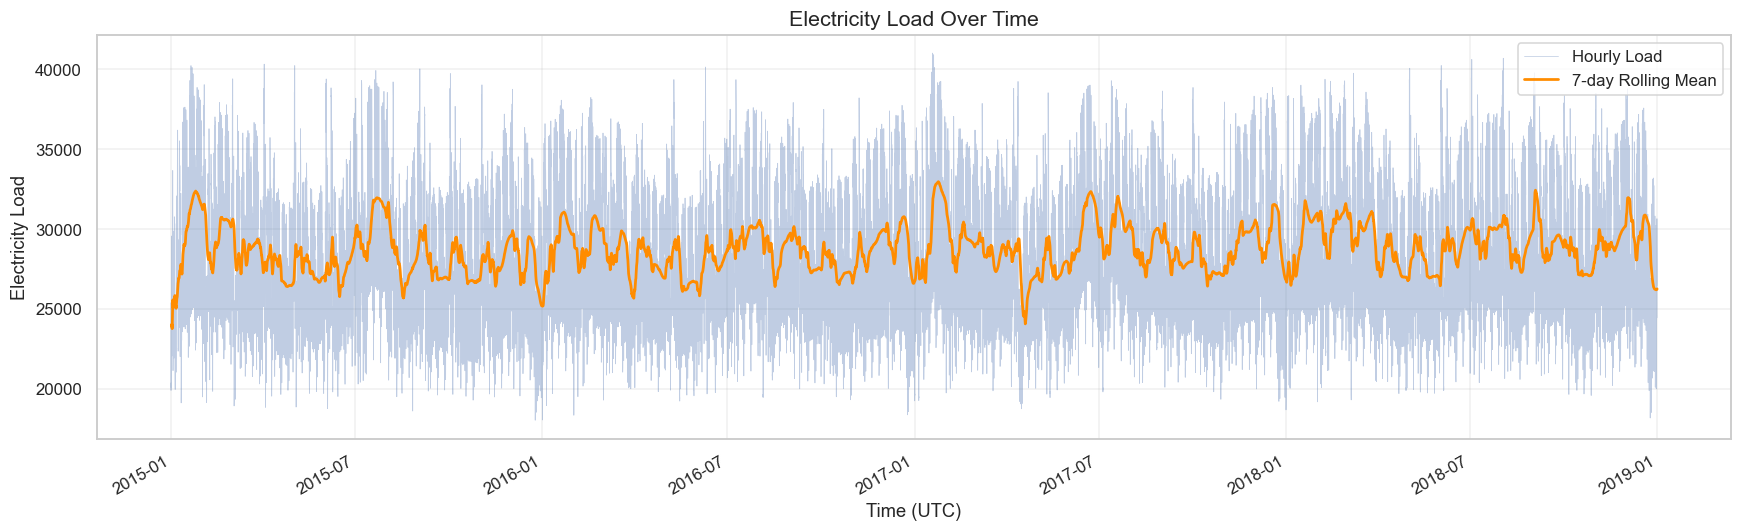

In [116]:
# Tính trung bình trượt 7 ngày (168 giờ)
load_series = df.set_index("time")["load"]
load_rolling = load_series.rolling(
    window=168,
    min_periods=24
).mean()

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(
    load_series.index,
    load_series,
    color=color_pal[0],
    linewidth=0.5,
    alpha=0.35,
    label="Hourly Load"
)
ax.plot(
    load_rolling.index,
    load_rolling,
    color="darkorange",
    linewidth=1.8,
    label="7-day Rolling Mean"
)
ax.set_title("Electricity Load Over Time", fontsize=14)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Electricity Load")
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### **Biểu đồ tương quan giữa Load và Temp**

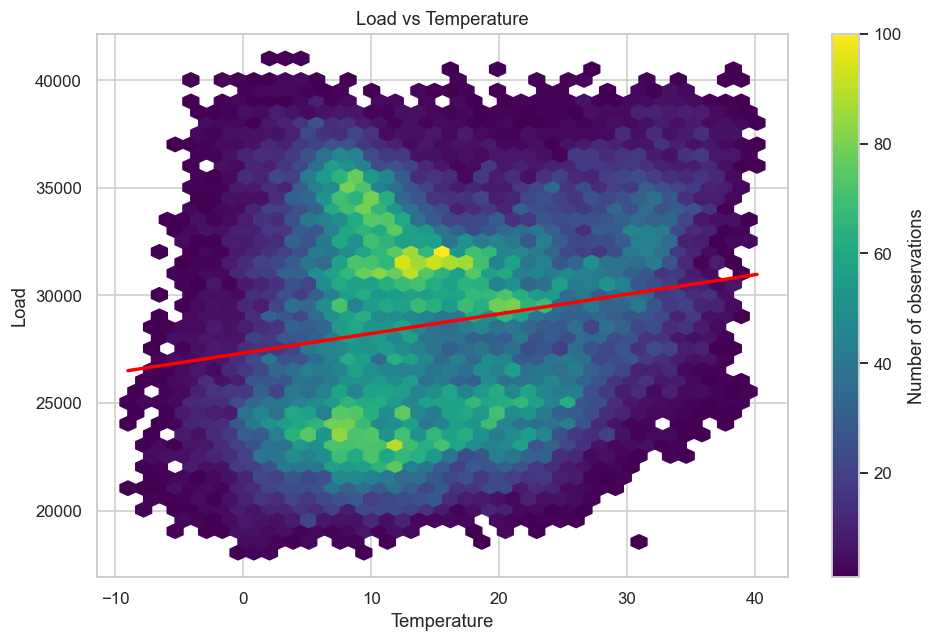

In [117]:
fig, ax = plt.subplots(figsize=(9, 6))

hb = ax.hexbin(
    df["temperature"],
    df["load"],
    gridsize=40,
    cmap="viridis",
    mincnt=1
)

plt.colorbar(hb, ax=ax, label="Number of observations")

sns.regplot(
    data=df,
    x="temperature",
    y="load",
    scatter=False,
    color="red",
    ci=None,
    ax=ax
)

ax.set_title("Load vs Temperature")
ax.set_xlabel("Temperature")
ax.set_ylabel("Load")

plt.tight_layout()
plt.show()


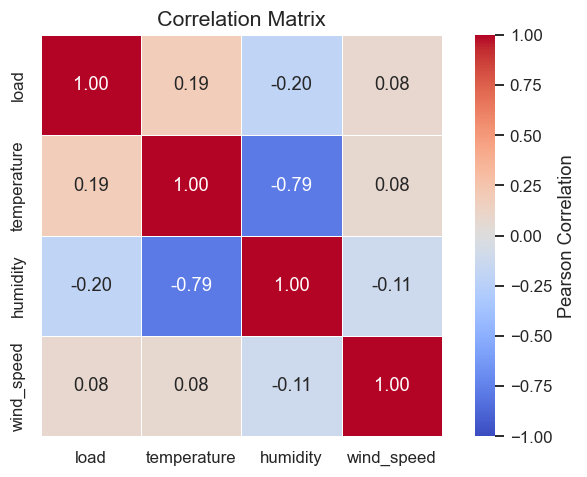

In [118]:
# Tính ma trận tương quan Pearson
corr_matrix = df[num_cols].corr(method="pearson")

# Vẽ heatmap
fig, ax = plt.subplots(figsize=(6.5, 4.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title("Correlation Matrix", fontsize=14)

plt.tight_layout()
plt.show()

# Ghi kết quả vào log
log.info(
    "Ma trận tương quan Pearson:\n%s",
    corr_matrix.round(3).to_string()
)

log.info("Hoàn thành Correlation Matrix.")

## **4. Preprocessing**

### **Chia tập dữ liệu theo thời gian**

In [119]:
from sklearn.preprocessing import StandardScaler

# Tạo DataFrame riêng phục vụ quá trình modeling
df_model = df.copy()
df.head()

,time,load,temperature,humidity,wind_speed
0,2014-12-31 23:00:00+00:00,25385.0,-5.825,63.0,1.0
1,2015-01-01 00:00:00+00:00,24382.0,-5.825,63.0,1.0
2,2015-01-01 01:00:00+00:00,22734.0,-6.964,64.0,1.0
3,2015-01-01 02:00:00+00:00,21286.0,-6.964,64.0,1.0
4,2015-01-01 03:00:00+00:00,20264.0,-6.964,64.0,1.0


In [120]:
# Xác định vị trí chia dữ liệu
n = len(df_model)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Chia dữ liệu theo thứ tự thời gian, không shuffle
train_df = df_model.iloc[:train_end].copy()
val_df = df_model.iloc[train_end:val_end].copy()
test_df = df_model.iloc[val_end:].copy()

In [121]:
# Kiểm tra kích thước các tập
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Samples": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Percentage": [
        len(train_df) / n * 100,
        len(val_df) / n * 100,
        len(test_df) / n * 100
    ],
    "Start Time": [
        train_df["time"].min(),
        val_df["time"].min(),
        test_df["time"].min()
    ],
    "End Time": [
        train_df["time"].max(),
        val_df["time"].max(),
        test_df["time"].max()
    ]
})

display(split_summary)

log.info("Hoàn thành chia dữ liệu theo thời gian.")
log.info("Train: %d | Validation: %d | Test: %d",
         len(train_df), len(val_df), len(test_df))

,Dataset,Samples,Percentage,Start Time,End Time
0,Train,24544,69.997718,2014-12-31 23:00:00+00:00,2017-10-19 14:00:00+00:00
1,Validation,5260,15.001141,2017-10-19 15:00:00+00:00,2018-05-26 18:00:00+00:00
2,Test,5260,15.001141,2018-05-26 19:00:00+00:00,2018-12-31 22:00:00+00:00


### **Chuẩn hóa dữ liệu**

In [122]:
# Khởi tạo StandardScaler
scaler = StandardScaler()

# Fit trên Train và transform cả ba tập
train_values = scaler.fit_transform(train_df[num_cols])

val_values = scaler.transform(val_df[num_cols])

test_values = scaler.transform(test_df[num_cols])

# Chuyển kết quả về DataFrame để giữ tên cột và timestamp
train_scaled = pd.DataFrame(
    train_values,
    columns=num_cols,
    index=pd.DatetimeIndex(train_df["time"], name="time")
)

val_scaled = pd.DataFrame(
    val_values,
    columns=num_cols,
    index=pd.DatetimeIndex(val_df["time"], name="time")
)

test_scaled = pd.DataFrame(
    test_values,
    columns=num_cols,
    index=pd.DatetimeIndex(test_df["time"], name="time")
)

log.info("Hoàn thành chuẩn hóa dữ liệu bằng StandardScaler.")

In [123]:
# Kiểm tra thống kê trên tập Train sau chuẩn hóa
print("=== TRAIN DATA AFTER SCALING ===")
display(train_scaled.describe().T.round(3))

print("=== VALIDATION DATA AFTER SCALING ===")
display(val_scaled.head())

print("=== TEST DATA AFTER SCALING ===")
display(test_scaled.head())

# Kiểm tra kích thước và thứ tự thời gian
assert len(train_scaled) + len(val_scaled) + len(test_scaled) == len(df)

assert train_scaled.index.max() < val_scaled.index.min()
assert val_scaled.index.max() < test_scaled.index.min()

assert train_scaled.index.is_monotonic_increasing
assert val_scaled.index.is_monotonic_increasing
assert test_scaled.index.is_monotonic_increasing

log.info("Kiểm tra dữ liệu sau Preprocessing thành công.")

=== TRAIN DATA AFTER SCALING ===


,count,mean,std,min,25%,50%,75%,max
load,24544.0,0.0,1.0,-2.317,-0.854,0.057,0.755,2.747
temperature,24544.0,0.0,1.0,-2.621,-0.759,-0.130,0.723,2.588
humidity,24544.0,0.0,1.0,-2.273,-0.871,0.010,0.892,1.733
wind_speed,24544.0,-0.0,1.0,-1.238,-0.735,-0.232,0.271,7.817


=== VALIDATION DATA AFTER SCALING ===


,load,temperature,humidity,wind_speed
time,,,,
2017-10-19 15:00:00+00:00,0.272099,0.193910,-0.470379,-0.231607
2017-10-19 16:00:00+00:00,0.259974,0.236258,-0.189957,1.277571
2017-10-19 17:00:00+00:00,0.530021,0.217202,0.090465,1.277571
2017-10-19 18:00:00+00:00,0.920430,0.025574,0.250706,0.774511
2017-10-19 19:00:00+00:00,0.689403,-0.164995,0.571189,-0.231607


=== TEST DATA AFTER SCALING ===


,load,temperature,humidity,wind_speed
time,,,,
2018-05-26 19:00:00+00:00,-0.431344,0.577165,-0.430318,-0.231607
2018-05-26 20:00:00+00:00,-0.530325,0.454354,0.090465,-0.734667
2018-05-26 21:00:00+00:00,-0.793537,0.157913,0.250706,-0.734667
2018-05-26 22:00:00+00:00,-1.151982,0.118741,0.090465,-0.231607
2018-05-26 23:00:00+00:00,-1.475156,-0.138527,0.811550,-1.237726


In [ ]:
def create_lstm_sequences(data, history=None, window_size=24):
    """
    Tạo chuỗi dữ liệu 3D cho LSTM.
    Mỗi mẫu sử dụng 24 giờ trước để dự báo load ở giờ tiếp theo.
    """

    # Ghép dữ liệu lịch sử nếu cần tạo window cho Validation/Test
    if history is not None:
        data_all = pd.concat([history.tail(window_size), data])
        start_pos = window_size
    else:
        data_all = data.copy()
        start_pos = window_size

    values = data_all[num_cols].to_numpy(dtype=np.float32)

    X, y = [], []

    for i in range(start_pos, len(data_all)):
        X.append(values[i - window_size:i])
        y.append(values[i, num_cols.index("load")])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

In [ ]:
# Tạo Lag Window cho từng tập dữ liệu
X_train_lstm, y_train_lstm = create_lstm_sequences(
    train_scaled
)

X_val_lstm, y_val_lstm = create_lstm_sequences(
    val_scaled,
    history=train_scaled
)

X_test_lstm, y_test_lstm = create_lstm_sequences(
    test_scaled,
    history=pd.concat([train_scaled, val_scaled])
)

# Kiểm tra kích thước
print("Train:", X_train_lstm.shape, y_train_lstm.shape)
print("Validation:", X_val_lstm.shape, y_val_lstm.shape)
print("Test:", X_test_lstm.shape, y_test_lstm.shape)

log.info("Hoàn thành tạo Lag Window cho LSTM.")

In [ ]:
def create_xgb_features(data, history=None, window_size=24):
    """
    Tạo Lag Features và Rolling Features cho XGBoost.
    Target là load tại thời điểm hiện tại,
    sử dụng các giá trị lịch sử làm đầu vào.
    """

    # Giữ lại lịch sử để tạo features liên tục giữa các tập
    if history is not None:
        data_all = pd.concat([history.tail(window_size + 1), data])
    else:
        data_all = data.copy()

    X = pd.DataFrame(index=data_all.index)

    # Tạo Lag Features cho cả 4 biến
    for col in num_cols:
        for lag in range(1, window_size + 1):
            X[f"{col}_lag_{lag}"] = data_all[col].shift(lag)

    # Rolling Features: chỉ sử dụng dữ liệu quá khứ
    past_load = data_all["load"].shift(1)

    X["load_rolling_mean_6h"] = (
        past_load.rolling(window=6).mean()
    )

    X["load_rolling_std_24h"] = (
        past_load.rolling(window=24).std()
    )

    # Chênh lệch load giữa hai thời điểm cách nhau 24 giờ
    X["load_trend_24h"] = (
        data_all["load"].shift(1)
        - data_all["load"].shift(25)
    )

    # Target: load tại thời điểm dự báo
    y = data_all["load"].rename("target_load")

    # Chỉ lấy những mẫu thuộc tập dữ liệu hiện tại
    X = X.loc[data.index]
    y = y.loc[data.index]

    # Loại bỏ các mẫu chưa đủ dữ liệu lịch sử
    valid_idx = X.notna().all(axis=1) & y.notna()

    return X.loc[valid_idx], y.loc[valid_idx]

In [ ]:
# Tạo features cho Train
X_train_xgb, y_train_xgb = create_xgb_features(
    train_scaled
)

# Validation sử dụng lịch sử cuối của Train
X_val_xgb, y_val_xgb = create_xgb_features(
    val_scaled,
    history=train_scaled
)

# Test sử dụng lịch sử của Train và Validation
X_test_xgb, y_test_xgb = create_xgb_features(
    test_scaled,
    history=pd.concat([train_scaled, val_scaled])
)

# Kiểm tra kích thước
print("Train:", X_train_xgb.shape, y_train_xgb.shape)
print("Validation:", X_val_xgb.shape, y_val_xgb.shape)
print("Test:", X_test_xgb.shape, y_test_xgb.shape)

log.info("Hoàn thành tạo Lag và Rolling Features cho XGBoost.")

In [ ]:
print("=== XGBOOST FEATURES ===")
display(X_train_xgb.head())

print("\n=== LSTM INPUT ===")
print(X_train_lstm[0])

print("\n=== LSTM TARGET ===")
print(y_train_lstm[0])

log.info("Hoàn thành kiểm tra Feature Engineering.")